# 02 · Amplitude Encoding and State Collapse

**Goal:** reproduce the state-collapse result from the jet data, first analytically (no circuit), then with a single Qiskit circuit as a cross-check.

| Section | Question | Poster output |
| --- | --- | --- |
| 1 | Which jets do we use? | Data box (counts, selection) |
| 2 | How different are the feature scales? | Fig. 1 — feature distributions |
| 3 | Where does amplitude encoding put the probability? | Fig. 2 — $|\alpha_{00}|^2$ histogram |
| 4 | What sets the size of the collapse? | Fig. 3 — $1-|\alpha_{00}|^2$ vs $p_T$ and $(m/p_T)^2$ |
| 5 | Does the encoded state depend on the choice of units? | Fig. 4 — GeV vs TeV |
| 6 | Does a real circuit reproduce the analytic probabilities? | Validation table, resource counts |

Figure titles are descriptive for now; they will be rewritten as findings once the real-data results are confirmed.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import matplotlib.pyplot as plt

from jet_data import (load_jets, select_quark_gluon, feature_matrix,
                      event_level_split, JET_FEATURES, FEATURE_LABELS)
from quantum_encodings import amplitude_probabilities
from figure_style import set_style, save, COLORS, SURFACE

set_style()
SEED = 42
rng = np.random.default_rng(SEED)

Matplotlib is building the font cache; this may take a moment.


## 1. Load and select jets

- Flavour labels use the **physics** definition recommended by the dataset: light quarks (u, d, s) → label 1, gluons → label 0.
- b, c and undefined jets (`isPhysOther`) are dropped; jets must pass the loose jet ID.
- The train/test split is done **per collision event** (run, lumi, event), so jets from the same event never end up on both sides.

In [2]:
raw = load_jets()
jets = select_quark_gluon(raw, require_loose_id=True)
X = feature_matrix(jets)                      # (n_jets, 4): pT, eta, phi, m  [float64]
y = jets["label"]
train, test = event_level_split(jets, test_fraction=0.3, seed=SEED)

n_raw, n_sel, n_q = len(raw["jetPt"]), len(y), int(y.sum())
print(f"Jets in file:               {n_raw:6d}")
print(f"  other flavour (b, c, ?):  {int((raw['isPhysOther'] == 1).sum()):6d}")
print(f"  fail loose jet ID:        {int((raw['jetLooseID'] != 1).sum()):6d}")
print(f"Selected quark + gluon:     {n_sel:6d}   quark {n_q}, gluon {n_sel - n_q}, quark fraction {n_q / n_sel:.3f}")
print(f"Event-level split:          train {int(train.sum())}, test {int(test.sum())}")

Jets in file:                28614
  other flavour (b, c, ?):   14702
  fail loose jet ID:             6
Selected quark + gluon:      13912   quark 5300, gluon 8612, quark fraction 0.381
Event-level split:          train 9729, test 4183


## 2. Feature scales

Amplitude encoding puts all four features into **one** normalised vector, so their relative sizes decide the quantum state.
$p_T$ is of order $10^2$–$10^3$ GeV, while $\eta$ and $\phi$ are of order 1.

saved figures/fig01_feature_distributions.pdf and .png


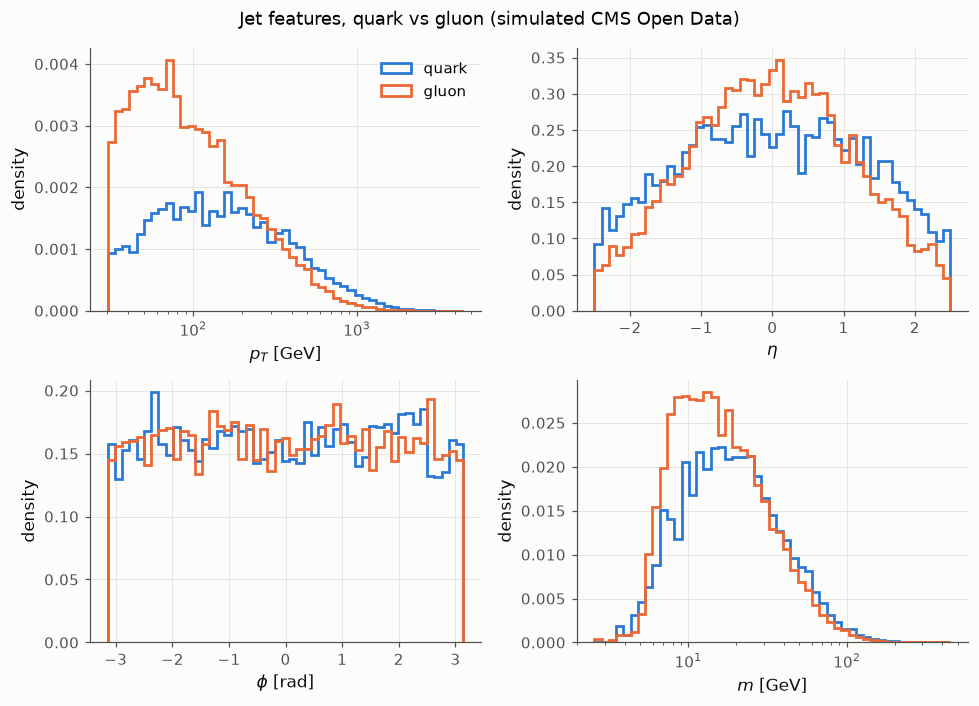

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.5))
for ax, (j, key) in zip(axes.ravel(), enumerate(JET_FEATURES)):
    values = X[:, j]
    if key in ("jetPt", "jetMass") and values.min() > 0:
        bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 50)
        ax.set_xscale("log")
    else:
        bins = np.linspace(values.min(), values.max(), 50)
    for label, name in ((1, "quark"), (0, "gluon")):
        ax.hist(values[y == label], bins=bins, density=True, histtype="step",
                linewidth=1.8, color=COLORS[name], label=name)
    ax.set_xlabel(FEATURE_LABELS[key])
    ax.set_ylabel("density")
axes[0, 0].legend()
fig.suptitle("Jet features, quark vs gluon (simulated CMS Open Data)")
fig.tight_layout()
save(fig, "fig01_feature_distributions")
plt.show()

In [4]:
pct = np.percentile(X, [5, 50, 95], axis=0)
rms = np.sqrt(np.mean(X**2, axis=0))
print(f"{'feature':10s} {'5%':>10s} {'median':>10s} {'95%':>10s} {'RMS':>10s}")
for j, key in enumerate(JET_FEATURES):
    print(f"{key:10s} {pct[0, j]:10.3f} {pct[1, j]:10.3f} {pct[2, j]:10.3f} {rms[j]:10.3f}")

feature            5%     median        95%        RMS
jetPt          50.225    258.872   1111.254    518.290
jetEta         -1.972     -0.010      1.955      1.183
jetPhi         -2.801      0.002      2.812      1.804
jetMass         8.255     27.944     97.278     48.688


## 3. Amplitude encoding without a circuit

With the ordering $x = (p_T, \eta, \phi, m)$ on two qubits,

$$|\psi(x)\rangle = \frac{1}{\lVert x\rVert}\big(p_T|00\rangle + \eta|01\rangle + \phi|10\rangle + m|11\rangle\big),
\qquad |\alpha_{00}|^2 = \frac{p_T^2}{p_T^2+\eta^2+\phi^2+m^2}.$$

The Born probabilities are fixed by the data alone, so they can be computed directly. Section 6 checks this against a circuit.

In [5]:
P = amplitude_probabilities(X)
a00 = P[:, 0]

print(f"median |a00|^2 = {np.median(a00):.4f}")
for t in (0.90, 0.98, 0.99, 0.999):
    print(f"fraction of jets with |a00|^2 > {t}: {np.mean(a00 > t):.3f}")
print()
for state, p in zip(["|00> pT", "|01> eta", "|10> phi", "|11> m"], P.mean(axis=0)):
    print(f"mean probability {state:9s} = {p:.2e}")

median |a00|^2 = 0.9861
fraction of jets with |a00|^2 > 0.9: 1.000
fraction of jets with |a00|^2 > 0.98: 0.672
fraction of jets with |a00|^2 > 0.99: 0.354
fraction of jets with |a00|^2 > 0.999: 0.001

mean probability |00> pT   = 9.83e-01
mean probability |01> eta  = 1.21e-04
mean probability |10> phi  = 2.42e-04
mean probability |11> m    = 1.67e-02


saved figures/fig02_alpha00_collapse.pdf and .png


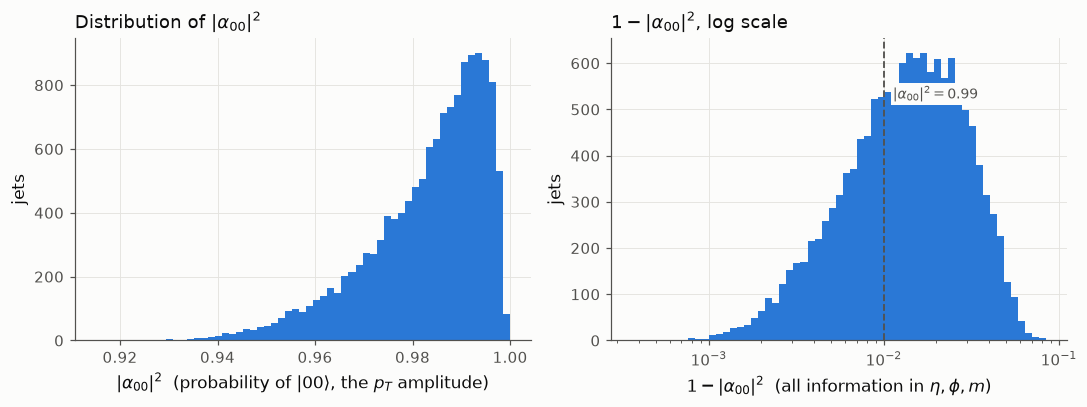

In [6]:
one_minus = 1.0 - a00

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.hist(a00, bins=np.linspace(a00.min(), 1.0, 60), histtype="stepfilled",
         color=COLORS["single"], linewidth=0)
ax1.set_xlabel(r"$|\alpha_{00}|^2$  (probability of $|00\rangle$, the $p_T$ amplitude)")
ax1.set_ylabel("jets")
ax1.set_title(r"Distribution of $|\alpha_{00}|^2$", loc="left")

bins = np.logspace(np.log10(one_minus.min()), np.log10(one_minus.max()), 60)
ax2.hist(one_minus, bins=bins, histtype="stepfilled", color=COLORS["single"], linewidth=0)
ax2.set_xscale("log")
ax2.axvline(0.01, color=COLORS["reference"], linestyle="--", linewidth=1.2)
ax2.annotate(r"$|\alpha_{00}|^2 = 0.99$", xy=(0.01, 0.80), xycoords=("data", "axes fraction"),
             xytext=(6, 0), textcoords="offset points", color=COLORS["reference"], fontsize=9,
             bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
ax2.set_xlabel(r"$1-|\alpha_{00}|^2$  (all information in $\eta, \phi, m$)")
ax2.set_ylabel("jets")
ax2.set_title(r"$1-|\alpha_{00}|^2$, log scale", loc="left")

fig.tight_layout()
save(fig, "fig02_alpha00_collapse")
plt.show()

## 4. What sets the size of the collapse?

$$1-|\alpha_{00}|^2 = \frac{\eta^2+\phi^2+m^2}{\lVert x\rVert^2} \approx \frac{m^2}{p_T^2} + \frac{\eta^2+\phi^2}{p_T^2}.$$

If the mass term dominates, the points in the right panel lie on the curve $r/(1+r)$ with $r=(m/p_T)^2$.

median share of m^2 in (eta^2 + phi^2 + m^2): 0.996
median m/pT: 0.118
saved figures/fig03_collapse_vs_pt.pdf and .png


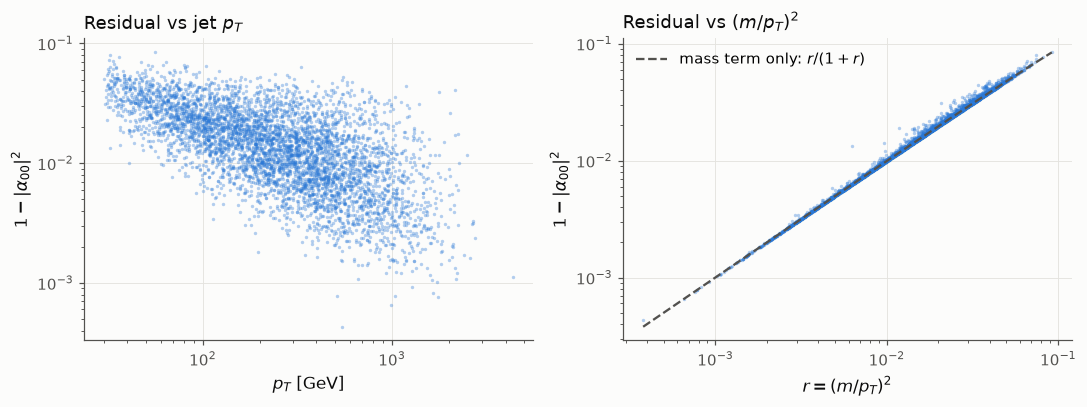

In [7]:
r_mass = (X[:, 3] / X[:, 0])**2
mass_share = X[:, 3]**2 / np.sum(X[:, 1:]**2, axis=1)   # share of m^2 in (eta^2 + phi^2 + m^2)
print(f"median share of m^2 in (eta^2 + phi^2 + m^2): {np.median(mass_share):.3f}")
print(f"median m/pT: {np.median(np.sqrt(r_mass)):.3f}")

idx = rng.choice(len(X), size=min(5000, len(X)), replace=False)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))

ax1.scatter(X[idx, 0], one_minus[idx], s=5, alpha=0.35, color=COLORS["single"], linewidths=0)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel(FEATURE_LABELS["jetPt"])
ax1.set_ylabel(r"$1-|\alpha_{00}|^2$")
ax1.set_title(r"Residual vs jet $p_T$", loc="left")

ax2.scatter(r_mass[idx], one_minus[idx], s=5, alpha=0.35, color=COLORS["single"], linewidths=0)
r_grid = np.logspace(np.log10(r_mass[idx].min()), np.log10(r_mass[idx].max()), 100)
ax2.plot(r_grid, r_grid / (1 + r_grid), color=COLORS["reference"], linestyle="--", linewidth=1.5,
         label=r"mass term only: $r/(1+r)$")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel(r"$r = (m/p_T)^2$")
ax2.set_ylabel(r"$1-|\alpha_{00}|^2$")
ax2.set_title(r"Residual vs $(m/p_T)^2$", loc="left")
ax2.legend(loc="upper left")

fig.tight_layout()
save(fig, "fig03_collapse_vs_pt")
plt.show()

## 5. Unit dependence

The L2 norm adds GeV² ($p_T$, $m$) to dimensionless or rad² quantities ($\eta$, $\phi$).
The same physical jets, written in TeV instead of GeV, give a completely different quantum state.

state           GeV        TeV
|00>         0.9829     0.0862
|01>         0.0001     0.3276
|10>         0.0002     0.5853
|11>         0.0167     0.0009
saved figures/fig04_unit_dependence.pdf and .png


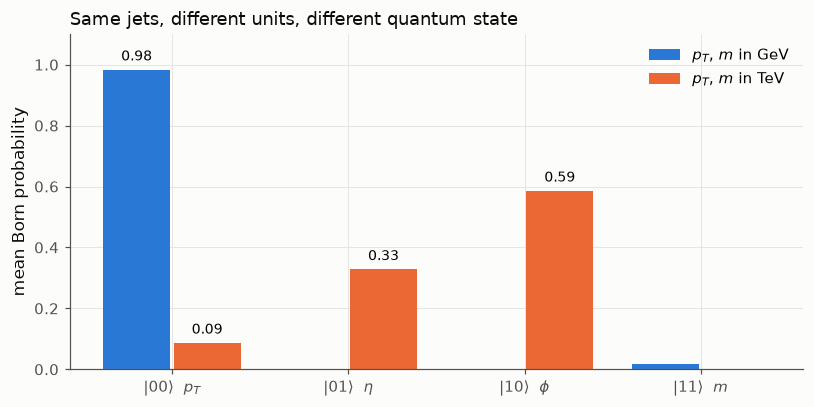

In [ ]:
X_tev = X.copy()
X_tev[:, [0, 3]] /= 1000.0
P_tev = amplitude_probabilities(X_tev)

states = [r"$|00\rangle$  $p_T$", r"$|01\rangle$  $\eta$", r"$|10\rangle$  $\phi$", r"$|11\rangle$  $m$"]
mean_gev, mean_tev = P.mean(axis=0), P_tev.mean(axis=0)

print(f"{'state':8s} {'GeV':>10s} {'TeV':>10s}")
for i in range(4):
    print(f"|{i:02b}>     {mean_gev[i]:10.4f} {mean_tev[i]:10.4f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
pos = np.arange(4)
width = 0.38
b1 = ax.bar(pos - width / 2 - 0.01, mean_gev, width, color=COLORS["series1"], label=r"$p_T$, $m$ in GeV")
b2 = ax.bar(pos + width / 2 + 0.01, mean_tev, width, color=COLORS["series2"], label=r"$p_T$, $m$ in TeV")
def bar_label(value):
    """Readable label for probabilities spanning several orders of magnitude."""
    if value >= 0.1:
        return f"{value:.2f}"
    if value >= 0.001:
        return f"{value:.3f}"
    return "<0.001"

for bars in (b1, b2):
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height + 0.02, bar_label(height),
                ha="center", va="bottom", fontsize=9)
ax.set_xticks(pos, states)
ax.set_ylim(0, 1.1)
ax.set_ylabel("mean Born probability")
ax.set_title("Same jets, different units, different quantum state", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "fig04_unit_dependence")
plt.show()

## 6. Circuit cross-check on a single jet

- **Statevector:** exact probabilities of the prepared state → differences are floating-point only (~1e-15).
- **StatevectorSampler:** finite shots → differences follow shot noise, $\sqrt{p(1-p)/N}$.

A typical jet is used (the one closest to the median $|\alpha_{00}|^2$).

In [9]:
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from quantum_encodings import amplitude_encoding_circuit, angle_encoding_circuit

i_jet = int(np.argmin(np.abs(a00 - np.median(a00))))
jet = X[i_jet]
p_target = P[i_jet]

qc = amplitude_encoding_circuit(jet)
p_exact = Statevector(qc).probabilities()

SHOTS = 10_000
qc_meas = qc.copy()
qc_meas.measure_all()
counts = StatevectorSampler(seed=SEED).run([qc_meas], shots=SHOTS).result()[0].data.meas.get_counts()
p_sampled = np.zeros(4)
for bitstring, c in counts.items():
    p_sampled[int(bitstring, 2)] = c / SHOTS

print(f"jet #{i_jet}: pT = {jet[0]:.1f} GeV, eta = {jet[1]:.3f}, phi = {jet[2]:.3f}, m = {jet[3]:.2f} GeV")
print(f"{'state':6s} {'analytic':>12s} {'Statevector':>12s} {'Sampler':>12s}")
for i in range(4):
    print(f"|{i:02b}>   {p_target[i]:12.4e} {p_exact[i]:12.4e} {p_sampled[i]:12.4e}")
print(f"max |Statevector - analytic| = {np.max(np.abs(p_exact - p_target)):.1e}")
print(f"max |Sampler - analytic|     = {np.max(np.abs(p_sampled - p_target)):.1e}   ({SHOTS} shots, seed {SEED})")

jet #3288: pT = 153.4 GeV, eta = -1.294, phi = -0.005, m = 18.17 GeV
state      analytic  Statevector      Sampler
|00>     9.8609e-01   9.8609e-01   9.8540e-01
|01>     7.0145e-05   7.0145e-05   0.0000e+00
|10>     1.0907e-09   1.0907e-09   0.0000e+00
|11>     1.3841e-02   1.3841e-02   1.4600e-02
max |Statevector - analytic| = 1.1e-16
max |Sampler - analytic|     = 7.6e-04   (10000 shots, seed 42)


In [10]:
# Resource cost of the two encodings for the same jet
lo, hi = X[train].min(axis=0), X[train].max(axis=0)
theta = np.pi * np.clip((jet - lo) / (hi - lo), 0, 1)     # min-max to [0, pi], fitted on train only
qc_angle = angle_encoding_circuit(theta)

basis = ["cx", "rz", "sx", "x"]
print(f"{'encoding':10s} {'qubits':>7s} {'depth':>6s} {'CNOTs':>6s}   gate counts")
for name, circuit in (("amplitude", qc), ("angle", qc_angle)):
    tqc = transpile(circuit, basis_gates=basis, optimization_level=1, seed_transpiler=SEED)
    ops = dict(tqc.count_ops())
    print(f"{name:10s} {tqc.num_qubits:7d} {tqc.depth():6d} {ops.get('cx', 0):6d}   {ops}")

print()
print(transpile(qc, basis_gates=basis, optimization_level=1, seed_transpiler=SEED).draw("text"))

encoding    qubits  depth  CNOTs   gate counts
amplitude        2      7      1   {'rz': 5, 'sx': 4, 'cx': 1}
angle            4      4      0   {'rz': 8, 'sx': 8}

global phase: 3π/4
     ┌─────────┐     ┌────┐    ┌────────────┐┌───┐┌────────────────┐┌────┐»
q_0: ┤ Rz(π/2) ├─────┤ √X ├────┤ Rz(3.1329) ├┤ X ├┤ Rz(-0.0081532) ├┤ √X ├»
     └──┬────┬─┘┌────┴────┴───┐└───┬────┬───┘└─┬─┘└────────────────┘└────┘»
q_1: ───┤ √X ├──┤ Rz(-2.9058) ├────┤ √X ├──────■──────────────────────────»
        └────┘  └─────────────┘    └────┘                                 »
«     ┌────────┐
«q_0: ┤ Rz(-π) ├
«     └────────┘
«q_1: ──────────
«               


## 7. Summary for the research log

Copy the printed lines into `notes/research_log.md`.

In [11]:
import qiskit
print(f"- Selection: {n_sel} quark+gluon jets (quark fraction {n_q / n_sel:.3f}); split train {int(train.sum())} / test {int(test.sum())}, seed {SEED}")
print(f"- |a00|^2 median {np.median(a00):.4f}; fraction > 0.99: {np.mean(a00 > 0.99):.3f}")
print(f"- Median share of m^2 in residual: {np.median(mass_share):.3f}; median m/pT {np.median(np.sqrt(r_mass)):.3f}")
print(f"- Mean P(|00>) GeV {mean_gev[0]:.3f} vs TeV {mean_tev[0]:.3f}")
print(f"- Circuit check: max |SV - analytic| {np.max(np.abs(p_exact - p_target)):.1e}; max |Sampler - analytic| {np.max(np.abs(p_sampled - p_target)):.1e} ({SHOTS} shots)")
print(f"- Qiskit {qiskit.__version__}")

- Selection: 13912 quark+gluon jets (quark fraction 0.381); split train 9729 / test 4183, seed 42
- |a00|^2 median 0.9861; fraction > 0.99: 0.354
- Median share of m^2 in residual: 0.996; median m/pT 0.118
- Mean P(|00>) GeV 0.983 vs TeV 0.086
- Circuit check: max |SV - analytic| 1.1e-16; max |Sampler - analytic| 7.6e-04 (10000 shots)
- Qiskit 2.6.1
